In [1]:
# Initialization, styling configuration, and helper utilities
%matplotlib inline

import numpy as np
import pandas as pd
import sklearn.datasets as ds
from IPython.display import Markdown, display
from ipywidgets import interact
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

# Course helpers: installed from PyPI in Colab, from the repository's .venv locally
import sys
if "google.colab" in sys.modules:
    %pip install -q dl-course
from dl_course import foundations as hp

hp.setup_theme()

# Representing Uncertainty

In almost every application of machine learning, we must quantify and manipulate uncertainty. We distinguish between two fundamental kinds of uncertainty:

- **Epistemic uncertainty** (*systematic uncertainty*):
  - Arises because we observe datasets of finite size.
  - Can be reduced by collecting more training data of the same type.
- **Aleatoric uncertainty** (*intrinsic / stochastic uncertainty / noise*):
  - Arises from unobserved variables, measurement noise, or inherent stochasticity.
  - Cannot be reduced simply by gathering more data of the same type; requires observing additional features or measurement modalities (e.g., adding a biopsy to a skin lesion image).

According to Pearl (1989), practical uncertainty emerges from:
- *Inherent stochasticity* — physical dynamics that are fundamentally random or chaotic
- *Incomplete observability* — inability to observe the state of all governing variables
- *Incomplete modeling* — practical models must discard non-essential factors to remain tractable

<small>📖 *Sources: [Bishop, C. M., & Bishop, H. (2024). Deep Learning: Foundations and Concepts. Springer](https://doi.org/10.1007/978-3-031-45468-4)*; [Pearl, J. (1989). Probabilistic Reasoning in Intelligent Systems. Morgan Kaufmann](https://doi.org/10.1016/C2009-0-27609-4)*</small>

> 📝 **Note:** Slides marked *(optional)* are self-study material that later lectures do not rely on: the non-invariance of modes and multivariate density transformations.

## Representing and Reasoning About Uncertainty

- **Frequentist approach**:
  - Defines probability as the relative frequency of repeatable events in the limit of infinitely many trials (e.g., coin flips, rolling dice).
- **Bayesian approach**:
  - Uses probability to quantify degrees of belief or uncertainty in propositions (e.g., whether a patient has a disease, or which side of a bent coin is heads when the coin cannot be inspected).
  - More general: includes frequentist probability as a special case.

In both viewpoints, probability theory acts as the rigorous extension of boolean logic to uncertain propositions (Cox, 1946; Darwiche, 2009):
- **Logic**: determines truth values given assumptions on other variables.
- **Probability theory**: determines the probability of a proposition given the probabilities of other propositions.

<small>📖 *Sources: [Cox, R. T. (1946). Probability, frequency and reasonable expectation. American Journal of Physics, 14(1), 1–13](https://doi.org/10.1119/1.1990764)*; [Darwiche, A. (2009). Modeling and Reasoning with Bayesian Networks. Cambridge University Press](https://doi.org/10.1017/CBO9780511811357)*</small>

## Random Variables

- Formally, a **random variable** $X$ is a quantity whose value is subject to variation due to chance. It can take specific realization values $x_i$ from a state space $\mathcal{X}$, with probability written formally as $p(X = x_i)$.
- **Compact Notation**: In machine learning, distinguishing $X$ and $x_i$ everywhere becomes cumbersome. Random variables share standard lowercase typography ($x \sim p(x)$, $\mathbf{x} \sim p(\mathbf{x})$); context distinguishes the random variable from a specific realization, while uppercase bold letters ($\mathbf{X} \in \mathbb{R}^{N \times D}$) are reserved for data matrices.
- A **vector-valued random variable** $\mathbf{x} \in \mathbb{R}^D$ takes column-vector values at random.
- Random variables can be:
  - **Discrete**: defined over a finite or countably infinite state space $\mathcal{X}$ (labels, integers).
  - **Continuous**: defined over an uncountably infinite real state space $\mathbb{R}$ or $\mathbb{R}^D$.

### Discrete Variables

- Formally, the probability that discrete variable $X$ takes state $x_i \in \mathcal{X}$ is denoted $p(X = x_i)$.
- In compact notation, the **probability mass function** (PMF) is written simply as $p(x)$:
  - The probability of taking value $x$: $p(x)$
  - Non-negativity: $\forall x \in \mathcal{X}, \quad 0 \leq p(x) \leq 1$
  - Normalization: $\sum_{x \in \mathcal{X}} p(x) = 1$

- *Example*: Tossing a fair coin has a uniform distribution:
  $$p(x) = \frac{1}{|\mathcal{X}|} = \frac{1}{2}, \qquad \mathcal{X} = \{\text{heads}, \text{tails}\}$$
  where $|\mathcal{X}|$ is the number of states.

### Joint Probability Distributions

- A probability distribution defined over multiple random variables is called a **joint probability distribution** $p(x, y)$.

Let $x$ denote tossing a fair coin with sample space $\mathcal{X} = \{\text{heads}, \text{tails}\}$ and $y$ throwing a fair six-sided die with sample space $\mathcal{Y} = \{1, \dots, 6\}$. How do we define the joint probability distribution $p(x, y)$?

Coin and die do not influence each other (they are *independent*, defined precisely below), so every one of the $|\mathcal{X}| \cdot |\mathcal{Y}| = 12$ combinations is equally likely:

$$p(x, y) = \frac{1}{|\mathcal{X}|} \cdot \frac{1}{|\mathcal{Y}|} = \frac{1}{2} \cdot \frac{1}{6} = \frac{1}{12}$$

*Question*: What is the probability of rolling a $3$ on the die, regardless of the coin toss outcome?

- **Marginal probability distribution**: a probability distribution over a subset of variables obtained by summing out (marginalizing) the remaining variables.
- **The Sum Rule of Probability**:

$$p(x) = \sum_{y \in \mathcal{Y}} p(x, y)$$

  If the joint probability is written as a table, marginal probabilities are the sums along the rows and columns on the *margin* of the table.

In our example:
$$p(y = 3) = p(x = \text{heads}, y = 3) + p(x = \text{tails}, y = 3) = \frac{1}{2} \cdot \frac{1}{6} + \frac{1}{2} \cdot \frac{1}{6} = \frac{1}{6}$$

## Conditional Probability and Bayes' Theorem

- **Conditional probability** of $y$ given $x$:
  $$p(y \mid x) = \frac{p(x, y)}{p(x)} \quad (\text{for } p(x) > 0)$$

- **The Product Rule of Probability**:
  $$p(x, y) = p(y \mid x) p(x)$$

- **Bayes' Theorem**:
  Combining the product rule with the sum rule yields:
  $$p(y \mid x) = \frac{p(x \mid y) p(y)}{p(x)} = \frac{p(x \mid y) p(y)}{\sum_{y'} p(x \mid y') p(y')}$$

  $$\text{posterior} = \frac{\text{likelihood} \times \text{prior}}{\text{marginal likelihood}}$$

## Problem: Conditional Probability

> 🎯 **Problem: Conditional Coin Selection**
>
> Roll a fair die $d$. If the outcome is odd, toss a fair coin; if it is even, toss a biased coin that shows heads with probability $0.7$. Let $c \in \{\text{heads}, \text{tails}\}$ be the outcome of the tossed coin.
> 1. What is $p(c = \text{tails} \mid d = \text{even})$?
> 2. What is the overall probability $p(c = \text{tails})$?
> 3. You only see that the coin shows tails. What is the probability that the die was even?

1. Given an even die, the biased coin is tossed: $p(c = \text{tails} \mid d = \text{even}) = 1 - 0.7 = 0.3$, and likewise $p(c = \text{tails} \mid d = \text{odd}) = 0.5$.
2. **Sum and product rule**: $p(c = \text{tails}) = \sum_{d} p(c = \text{tails} \mid d)\, p(d) = 0.5 \cdot 0.5 + 0.3 \cdot 0.5 = 0.4$
3. **Bayes' theorem**:
$$p(d = \text{even} \mid c = \text{tails}) = \frac{p(c = \text{tails} \mid d = \text{even})\, p(d = \text{even})}{p(c = \text{tails})} = \frac{0.3 \cdot 0.5}{0.4} = 0.375$$
   Seeing tails makes the even (biased) branch *less* likely than its prior $0.5$, because the biased coin rarely shows tails.

## Problem: Medical Screening with Bayes' Theorem

> 🎯 **Problem: Does a patient have cancer or not?**
>
> A patient takes a screening test and receives a positive result ($+$). From epidemiological data:
> - Prior prevalence of cancer in the population: $p(\text{cancer}) = 0.008$ (so $p(\neg\text{cancer}) = 0.992$).
> - True positive rate (sensitivity): $p(+ \mid \text{cancer}) = 0.98$ (false negative: $p(- \mid \text{cancer}) = 0.02$).
> - True negative rate (specificity): $p(- \mid \neg\text{cancer}) = 0.97$ (false positive: $p(+ \mid \neg\text{cancer}) = 0.03$).

- **Question**: Given a positive test result ($+$), what is the posterior probability $p(\text{cancer} \mid +)$ that the patient actually has cancer?

## Solution: Medical Screening with Bayes' Theorem

- **Given Parameters**: Prior $p(\text{cancer}) = 0.008$, Sensitivity $p(+ \mid \text{cancer}) = 0.98$, False Alarm $p(+ \mid \neg\text{cancer}) = 0.03$.
- Applying **Bayes' Theorem** with the **sum rule**:
  $$p(\text{cancer} \mid +) = \frac{p(+ \mid \text{cancer}) p(\text{cancer})}{p(+ \mid \text{cancer}) p(\text{cancer}) + p(+ \mid \neg\text{cancer}) p(\neg\text{cancer})}$$
  $$p(\text{cancer} \mid +) = \frac{(0.98)(0.008)}{(0.98)(0.008) + (0.03)(0.992)} = \frac{0.00784}{0.00784 + 0.02976} = \frac{0.00784}{0.0376} \approx 0.2085 \quad (20.9\%)$$

- **Natural Frequencies Intuition (out of 100,000 patients)**:
  - $800$ have cancer $\to$ $784$ test positive ($\mathrm{TP}$).
  - $99,200$ are healthy $\to$ $2,976$ test positive ($\mathrm{FP}$).
  - Total positive tests $= 784 + 2,976 = 3,760$. Actual cancer $= \frac{784}{3,760} \approx 20.9\%$.

> 💡 **Key Takeaway:** Even with 98% sensitivity and 97% specificity, because the base rate (0.8%) is low, a positive result implies only a ~21% probability of disease. False alarms ($2.98\%$) outnumber true positives ($0.78\%$).

### Independence

- Reconsider rolling a die and tossing a fair coin: knowing the die outcome provides zero information about the coin flip outcome.
- Two random variables $x$ and $y$ are **statistically independent** (denoted $x \perp\!\!\!\perp y$) if their joint distribution factorizes into the product of their marginals:

$$p(x, y) = p(x) p(y)$$

- Under independence, conditional distributions reduce to marginals:
  $$p(x \mid y) = \frac{p(x, y)}{p(y)} = \frac{p(x) p(y)}{p(y)} = p(x)$$

### Conditional Independence

- Two random variables $x$ and $y$ are **conditionally independent** given a third variable $z$ (denoted $x \perp\!\!\!\perp y \mid z$) if:

$$p(x, y \mid z) = p(x \mid z) p(y \mid z)$$

- Equivalently: $p(x \mid y, z) = p(x \mid z)$.
- *Note*: Statistical independence is fundamentally different from mutual exclusivity (mutually exclusive events with non-zero probability can never be independent, since if one occurs the other cannot).

## Chain Rule of Probability

- Applying the product rule repeatedly to a joint distribution over $D$ variables yields the **chain rule of probability**:

$$p(x_1, \dots, x_D) = p(x_1) p(x_2 \mid x_1) p(x_3 \mid x_1, x_2) \dots p(x_D \mid x_1, \dots, x_{D-1}) = \prod_{i=1}^D p(x_i \mid x_1, \dots, x_{i-1})$$

- Holds universally for any joint probability distribution, regardless of independence properties.

## Problem: Conditional Independence

> 🎯 **Problem: Security System Alarm**
>
> A company employs two security guards $a$ and $b$ and an automated alarm $r \in \{0, 1\}$ that rings with prior probability $p(r = 1) = 0.001$:
> - When the alarm rings, $a$ calls the police with probability $0.9$, and $b$ with probability $0.5$.
> - When it does not ring, $a$ calls with probability $0.05$, and $b$ with probability $0.01$.
> - The calls are conditionally independent given the alarm: $a \perp\!\!\!\perp b \mid r$.
> 1. What is the probability that both guards call, given that the alarm rings?
> 2. Both guards call. What is the probability that the alarm rang?

1. Conditional independence lets the joint factorize:
$$p(a = 1, b = 1 \mid r = 1) = p(a = 1 \mid r = 1)\, p(b = 1 \mid r = 1) = 0.9 \cdot 0.5 = 0.45$$
2. With $p(a = 1, b = 1 \mid r = 0) = 0.05 \cdot 0.01 = 0.0005$, Bayes' theorem gives
$$p(r = 1 \mid a = 1, b = 1) = \frac{0.45 \cdot 0.001}{0.45 \cdot 0.001 + 0.0005 \cdot 0.999} \approx 0.47$$
   Two independent calls raise the probability of a real alarm from $0.1\%$ to almost $50\%$.

### Continuous Variables and Densities

- The probability distribution of a continuous random variable $x$ is described by a **probability density function** (PDF) $p(x)$:
  - Non-negativity: $\forall x \in \mathbb{R}, \quad p(x) \geq 0$
  - Normalization: $\int_{-\infty}^{\infty} p(x) \, dx = 1$

- Probability of falling in an infinitesimal interval $(x, x + \delta x)$:
  $$p(x \in (x, x + \delta x)) \simeq p(x) \, \delta x \quad (\text{as } \delta x \to 0)$$
- Probability of falling in a finite interval $[a, b]$:
  $$p(x \in [a, b]) = \int_a^b p(x) \, dx$$

- **Cumulative Distribution Function (CDF)**:
  The probability that $x$ lies in the interval $(-\infty, z)$ is given by the CDF $P(z)$:
  $$P(z) = p(x \leq z) = \int_{-\infty}^z p(x) \, dx, \qquad p(x) = \frac{d P(x)}{dx}$$

- Continuous **Sum Rule**: $p(x) = \int p(x, y) \, dy$.

## Expectation, Variance, and Sample Averages

- **Expectation** of a function $f(x)$ (weighted average under a probability distribution); for $f(x) = x$ it is the **mean** $\mu = \mathbb{E}[x]$:
  $$\mathbb{E}[f] = \sum_{x} p(x) f(x) \quad (\text{discrete}), \qquad \mathbb{E}[f] = \int p(x) f(x) \, dx \quad (\text{continuous})$$

- **Sample average approximation**:
  Given $N$ independent samples $x_1, \dots, x_N \sim p(x)$, expectations can be approximated by finite sums:
  $$\mathbb{E}[f] \simeq \frac{1}{N} \sum_{n=1}^N f(x_n) \quad (\text{exact as } N \to \infty)$$

- **Conditional expectation**:
  $$\mathbb{E}_x[f \mid y] = \sum_x p(x \mid y) f(x)$$

- **Variance** (measures dispersion around the mean):
  $$\mathrm{var}[f] = \mathbb{E}\left[ \{f(x) - \mathbb{E}[f(x)]\}^2 \right] = \mathbb{E}[f(x)^2] - \mathbb{E}[f(x)]^2$$
  Standard deviation is $\sigma = \sqrt{\mathrm{var}[x]}$.

## Covariance and Correlation

- **Scalar Covariance** measures the extent to which two random variables vary together:
  $$\mathrm{cov}[x, y] = \mathbb{E}[(x - \mathbb{E}[x])(y - \mathbb{E}[y])] = \mathbb{E}[xy] - \mathbb{E}[x]\mathbb{E}[y]$$

- **Vector Covariance Matrix**:
  For two random vectors $\mathbf{x} \in \mathbb{R}^D$ and $\mathbf{y} \in \mathbb{R}^M$, the covariance is a $D \times M$ matrix:
  $$\mathrm{cov}[\mathbf{x}, \mathbf{y}] = \mathbb{E}\left[ (\mathbf{x} - \mathbb{E}[\mathbf{x}])(\mathbf{y} - \mathbb{E}[\mathbf{y}])^\mathrm{T} \right] = \mathbb{E}[\mathbf{x}\mathbf{y}^\mathrm{T}] - \mathbb{E}[\mathbf{x}]\mathbb{E}[\mathbf{y}]^\mathrm{T}$$
  Auto-covariance of a vector: $\mathrm{cov}[\mathbf{x}] \equiv \mathrm{cov}[\mathbf{x}, \mathbf{x}] \in \mathbb{R}^{D \times D}$.

- **Pearson Correlation** (normalized scale-invariant measure):
  $$\rho(x, y) = \frac{\mathrm{cov}[x, y]}{\sqrt{\mathrm{var}[x] \, \mathrm{var}[y]}} \in [-1, 1]$$

- *Independence vs. Uncorrelatedness*: If $x$ and $y$ are independent, $\mathrm{cov}[x, y] = 0$. However, zero covariance does **not** imply independence (e.g., nonlinear dependencies).

In [2]:
# Synthetic dataset: five columns with different kinds of dependence
rng = np.random.default_rng(0)
n_samples = 100
X_circles, _ = ds.make_circles(n_samples=n_samples, random_state=0)
noise = rng.normal(0, 1, size=n_samples)
ramp = np.linspace(0, 1, num=n_samples)

data = pd.DataFrame({
    'x0': X_circles[:, 0] * 10,   # point on a circle (x-coordinate), scaled by 10
    'x1': X_circles[:, 1],        # same point (y-coordinate): dependent on x0, but uncorrelated
    'x2': -ramp * noise,          # depends linearly on x3, with a growing slope
    'x3': noise,
    'x4': rng.normal(-2, 1, size=n_samples),  # independent of all other columns
})
data.head(3)

,x0,x1,x2,x3,x4
0,-9.921147,-0.125333,-0.000000,0.125730,-1.497317
1,-1.499051,-0.785830,0.001334,-0.132105,-1.010287
2,9.685832,0.248690,-0.012938,0.640423,-2.164295


- `x0`, `x1`: coordinates of points on two circles. They are **dependent** (knowing one restricts the other) but their correlation is about $0$: uncorrelated does not mean independent.
- `x2`, `x3`: `x2` is `x3` times a negative factor, so they are strongly (negatively) correlated.
- `x4`: drawn independently of everything else.
- `x0` is scaled by $10$: its covariances grow by $10$, its correlations do not change.

In [3]:
# Empirical covariance and correlation matrices (pandas divides by N - 1, see Bessel's correction below)
display(Markdown("Covariance matrix:"))
display(data.cov().round(2))
display(Markdown("Correlation matrix:"))
display(data.corr().round(2))

Covariance matrix:

,x0,x1,x2,x3,x4
x0,41.41,0.00,0.24,-0.29,-0.26
x1,0.00,0.41,-0.02,0.03,0.01
x2,0.24,-0.02,0.35,-0.51,-0.03
x3,-0.29,0.03,-0.51,0.94,0.05
x4,-0.26,0.01,-0.03,0.05,0.92


Correlation matrix:

,x0,x1,x2,x3,x4
x0,1.00,0.00,0.06,-0.05,-0.04
x1,0.00,1.00,-0.06,0.04,0.02
x2,0.06,-0.06,1.00,-0.89,-0.06
x3,-0.05,0.04,-0.89,1.00,0.06
x4,-0.04,0.02,-0.06,0.06,1.00


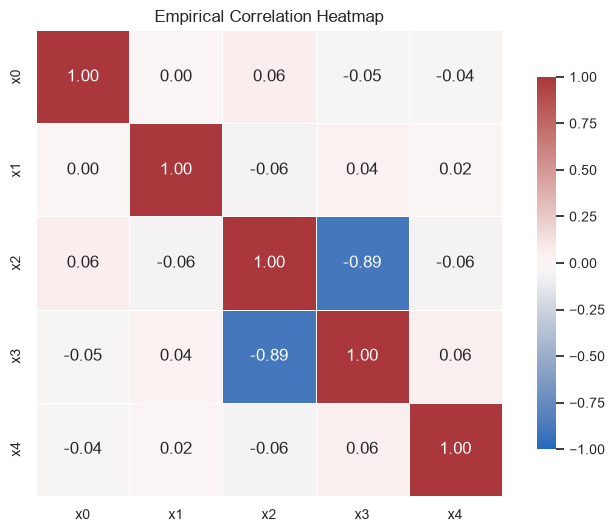

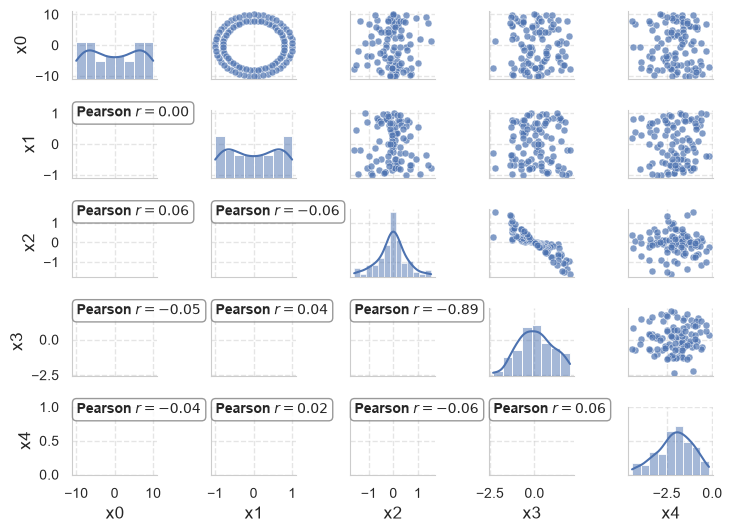

In [4]:
# Visualize empirical pairwise relationships and correlation matrix
hp.plot_correlation_matrix_and_pairgrid(data)

# Standard Probability Distributions

## Discrete Distributions

- **Bernoulli distribution** $\mathrm{Bern}(x \mid \mu)$:
  Models a single binary outcome $x \in \{0, 1\}$ governed by mean parameter $\mu \in [0, 1]$:
  $$p(x \mid \mu) = \mu^x (1 - \mu)^{1 - x}$$
  $$\mathbb{E}[x] = \mu, \qquad \mathrm{var}[x] = \mu(1 - \mu)$$

- **Categorical distribution**:
  Generalizes Bernoulli to $K$ mutually exclusive categories using a 1-of-$K$ binary encoding vector $\mathbf{x} \in \{0, 1\}^K$ where $\sum_{k=1}^K x_k = 1$:
  $$p(\mathbf{x} \mid \boldsymbol{\mu}) = \prod_{k=1}^K \mu_k^{x_k}, \qquad \mu_k \geq 0, \quad \sum_{k=1}^K \mu_k = 1$$
  $$\mathbb{E}[x_k] = \mu_k, \qquad \mathrm{var}[x_k] = \mu_k(1 - \mu_k)$$

## The Gaussian (Normal) Distribution

- For continuous variables over $\mathbb{R}$, the most ubiquitous distribution is the **Gaussian distribution** $\mathcal{N}(x \mid \mu, \sigma^2)$:

$$\mathcal{N}(x \mid \mu, \sigma^2) = \frac{1}{(2\pi\sigma^2)^{1/2}} \exp\left\{ -\frac{1}{2\sigma^2}(x - \mu)^2 \right\}$$

  where $\mu = \mathbb{E}[x]$ is the mean, $\sigma^2 = \mathrm{var}[x]$ is the variance, and $\beta = \frac{1}{\sigma^2}$ is the precision.

- **Why the Gaussian?**
  - **Central Limit Theorem**: Subject to mild conditions, the sum of many independent and identically distributed (i.i.d.) random variables tends toward a Gaussian distribution, irrespective of their original shape (demonstrated below).
  - **Maximum Entropy**: Out of all continuous distributions with a given mean and variance, the Gaussian maximizes the differential entropy *(→ Lecture 03_information)*, i.e. it encodes the fewest assumptions beyond mean and variance.

In [5]:
# Sample from two Gaussians and a uniform distribution, then compare sample moments with the true ones
n_draws = 100_000
samples = {
    "Gaussian, σ = 20": rng.normal(loc=0.0, scale=20.0, size=n_draws),
    "Gaussian, σ = 10": rng.normal(loc=0.0, scale=10.0, size=n_draws),
    "Uniform on [-100, 100]": rng.uniform(low=-100.0, high=100.0, size=n_draws),
}
true_var = {"Gaussian, σ = 20": 20.0**2, "Gaussian, σ = 10": 10.0**2, "Uniform on [-100, 100]": 200.0**2 / 12}

rows = ["| Distribution | sample mean | true mean | sample variance | true variance |", "| :-- | --: | --: | --: | --: |"]
for name, x in samples.items():
    rows.append(f"| {name} | {x.mean():.2f} | 0 | {x.var():.1f} | {true_var[name]:.1f} |")
display(Markdown("\n".join(rows)))

| Distribution | sample mean | true mean | sample variance | true variance |
| :-- | --: | --: | --: | --: |
| Gaussian, σ = 20 | -0.02 | 0 | 400.1 | 400.0 |
| Gaussian, σ = 10 | 0.01 | 0 | 100.5 | 100.0 |
| Uniform on [-100, 100] | -0.19 | 0 | 3337.1 | 3333.3 |

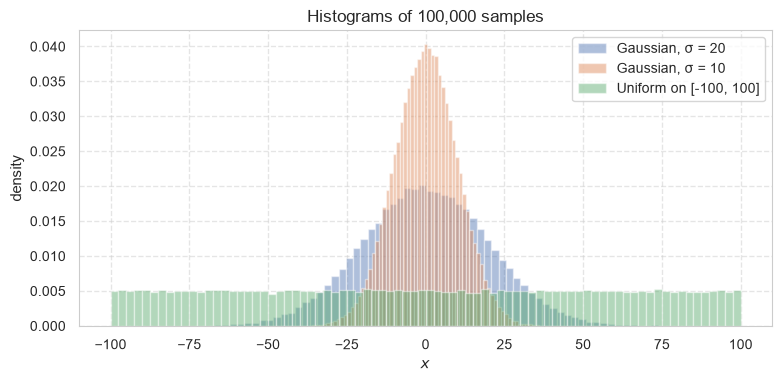

In [6]:
hp.plot_sample_histograms(samples, title="Histograms of 100,000 samples")

### The Central Limit Theorem in Action

- Average $N$ i.i.d. uniform variables on $[0, 1]$: for $N = 1$ the histogram is flat, and as $N$ grows it approaches a Gaussian with mean $0.5$ and variance $\frac{1}{12N}$.

N = 1: sample variance 0.0837, theory $1/(12N)$ = 0.0833

N = 2: sample variance 0.0417, theory $1/(12N)$ = 0.0417

N = 10: sample variance 0.0083, theory $1/(12N)$ = 0.0083

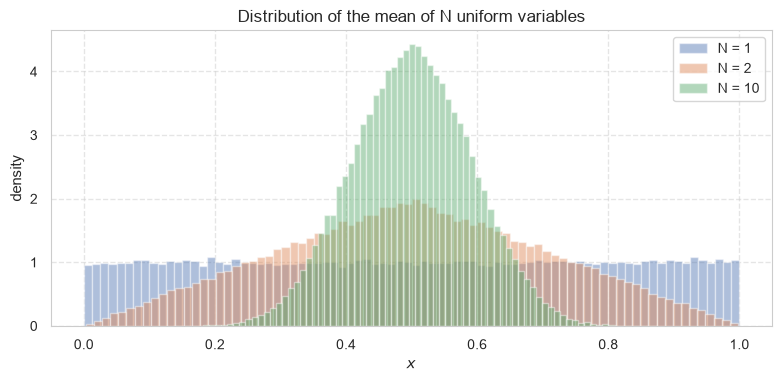

In [7]:
# Means of N uniform variables, 100,000 times each
clt_samples = {f"N = {N}": rng.uniform(0.0, 1.0, size=(n_draws, N)).mean(axis=1) for N in (1, 2, 10)}
for name, x in clt_samples.items():
    N = int(name.split("= ")[1])
    display(Markdown(f"{name}: sample variance {x.var():.4f}, theory $1/(12N)$ = {1 / (12 * N):.4f}"))
hp.plot_sample_histograms(clt_samples, title="Distribution of the mean of N uniform variables")

## Maximum Likelihood for the Gaussian

Suppose we observe a dataset of $N$ independent and identically distributed (i.i.d.) observations $\mathbf{x} = (x_1, \dots, x_N)^\mathrm{T}$. The probability of the dataset given $\mu$ and $\sigma^2$ is the **likelihood function**:

$$p(\mathbf{x} \mid \mu, \sigma^2) = \prod_{n=1}^N \mathcal{N}(x_n \mid \mu, \sigma^2)$$

Taking the logarithm yields the **log-likelihood function**:
$$\ln p(\mathbf{x} \mid \mu, \sigma^2) = -\frac{N}{2}\ln(2\pi) - \frac{N}{2}\ln \sigma^2 - \frac{1}{2\sigma^2}\sum_{n=1}^N (x_n - \mu)^2$$

Setting the derivatives with respect to $\mu$ and $\sigma^2$ to zero yields the **maximum likelihood estimators** (MLEs):

$$\mu_\mathrm{ML} = \frac{1}{N}\sum_{n=1}^N x_n, \qquad \sigma_\mathrm{ML}^2 = \frac{1}{N}\sum_{n=1}^N (x_n - \mu_\mathrm{ML})^2$$

## Bias of Maximum Likelihood Estimators

Evaluating the expectations of the ML estimators under the true generating distribution:

$$\mathbb{E}[\mu_\mathrm{ML}] = \mu \quad (\text{unbiased})$$
$$\mathbb{E}[\sigma_\mathrm{ML}^2] = \left(\frac{N - 1}{N}\right)\sigma^2 \quad (\text{biased!})$$

> ⚠️ **Important: The Maximum Likelihood Variance is Systematically Biased!**
> Because the sample variance is computed relative to the sample mean $\mu_\mathrm{ML}$ rather than the true mean $\mu$, it underestimates the true variance by a factor of $\frac{N-1}{N}$.

- **Bessel's correction** yields the unbiased variance estimator $\tilde{\sigma}^2$:
  $$\tilde{\sigma}^2 = \frac{N}{N - 1}\sigma_\mathrm{ML}^2 = \frac{1}{N - 1}\sum_{n=1}^N (x_n - \mu_\mathrm{ML})^2$$
- As $N \to \infty$ the bias vanishes, and for anything other than small $N$ it is not a serious problem. It is, however, closely related to the problem of **over-fitting** that we meet with models of many parameters.

In [8]:
# Numerical check of the bias: many datasets of size N from a Gaussian with variance 1
N_small = 2
datasets = rng.normal(0.0, 1.0, size=(100_000, N_small))
var_ml = datasets.var(axis=1, ddof=0).mean()        # divides by N
var_unbiased = datasets.var(axis=1, ddof=1).mean()  # divides by N - 1 (Bessel)
display(Markdown(f"$N = {N_small}$: average $\\sigma^2_\\mathrm{{ML}}$ = {var_ml:.3f} (theory $(N-1)/N$ = {(N_small - 1) / N_small:.3f}), "
                 f"average $\\tilde{{\\sigma}}^2$ = {var_unbiased:.3f} (theory 1)"))

$N = 2$: average $\sigma^2_\mathrm{ML}$ = 0.499 (theory $(N-1)/N$ = 0.500), average $\tilde{\sigma}^2$ = 0.998 (theory 1)

# Probabilistic Linear Regression

We can express regression in a probabilistic framework by assuming the target variable $t$ is generated by a deterministic model $y(x, \mathbf{w})$ corrupted by additive zero-mean Gaussian noise $\epsilon \sim \mathcal{N}(0, \sigma^2)$:

$$t = y(x, \mathbf{w}) + \epsilon \implies p(t \mid x, \mathbf{w}, \sigma^2) = \mathcal{N}(t \mid y(x, \mathbf{w}), \sigma^2)$$

Assuming training target values $\mathbf{t} = (t_1, \dots, t_N)^\mathrm{T}$ are drawn independently, the log-likelihood is:
$$\ln p(\mathbf{t} \mid \mathbf{x}, \mathbf{w}, \sigma^2) = -\frac{N}{2}\ln(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{n=1}^N \{y(x_n, \mathbf{w}) - t_n\}^2$$

> 💡 **Key Takeaway:** Maximizing likelihood under Gaussian noise is mathematically identical to minimizing the **sum-of-squares loss**:

$$E(\mathbf{w}) = \frac{1}{2}\sum_{n=1}^N \{y(x_n, \mathbf{w}) - t_n\}^2$$

> 📝 **Note:** Here $\mathbf{x} = (x_1, \dots, x_N)^\mathrm{T}$ collects the inputs of the training data. The closed-form solution and its geometry follow in *(→ Lecture 04_regression)*.

## Model Complexity: A First Look

- How flexible should the model $y(x, \mathbf{w})$ be? A polynomial of degree $M$ has $M + 1$ weights.
- Too simple a model misses the structure of the data (**underfitting**); too flexible a model also fits the noise (**overfitting**).
- The **bias–variance decomposition** makes this trade-off precise *(→ Lecture 04_regression)*.

We explore polynomial models of degree $M \in \{1, \dots, 9\}$ on a small dataset `model_example.csv` with $22$ observations:
- `Budget` $x \in \{1, \dots, 22\}$ (input), `Revenue` $t$ (target, observed with noise),
- `Generator` $f(x) = \ln x$: the true function that generated the revenue before the noise was added.

In [9]:
df = pd.read_csv(hp.get_file("model_example.csv"), sep=";")
x_budget = df.Budget.values.reshape(-1, 1)   # inputs as an N x 1 matrix (as scikit-learn expects)
t_revenue = df.Revenue.values                 # targets
x_grid = np.linspace(1.0, 25.0, 400).reshape(-1, 1)  # dense grid for drawing curves
df.head(3)

,Budget,Generator,Revenue
0,1,0.000000,0.430000
1,2,0.693147,1.483147
2,3,1.098612,0.838612


In [10]:
@interact(show_generator=False)
def plot_generator_data(show_generator=False):
    curves = {r"Generator $f(x) = \ln x$": np.log(x_grid)} if show_generator else {}
    hp.plot_fitted_curves(df.Budget, df.Revenue, x_grid, curves, xlabel="Budget", ylabel="Revenue")

interactive(children=(Checkbox(value=False, description='show_generator'), Output()), _dom_classes=('widget-in…

In [11]:
# Baseline: a straight line (degree M = 1)
lin_model = LinearRegression().fit(x_budget, t_revenue)

# Concrete numerical input and prediction demonstration
sample_budget = np.array([[10.0]])
base_pred = lin_model.predict(sample_budget)
display(Markdown(
    r"**Baseline Linear Model Verification**:"
    + f"\n- Sample Input (Budget): `{sample_budget[0, 0]:.1f}`"
    + f"\n- Model Prediction (Revenue): `{base_pred[0]:.2f}`"
    + f"\n- Learned Parameters: $w_1 = {lin_model.coef_[0]:.4f}, w_0 = {lin_model.intercept_:.4f}$"
))

**Baseline Linear Model Verification**:
- Sample Input (Budget): `10.0`
- Model Prediction (Revenue): `2.10`
- Learned Parameters: $w_1 = 0.1306, w_0 = 0.7931$

In [12]:
x_max = 25.0  # rescale inputs to [0, 1]: powers up to x^9 of raw budgets (up to 22^9) make least squares ill-conditioned


def fit_polynomial(x, t, M):
    """Least-squares fit of a polynomial of degree M in x / x_max; returns the feature map and the fitted model."""
    features = PolynomialFeatures(degree=M)
    model = LinearRegression().fit(features.fit_transform(x / x_max), t)
    return features, model


def predict_polynomial(fit, x):
    """Predictions y(x, w) of a fitted polynomial."""
    features, model = fit
    return model.predict(features.transform(x / x_max))


# Fit all degrees and compare the training error
fits = {M: fit_polynomial(x_budget, t_revenue, M) for M in range(1, 10)}
rows = ["| Degree $M$ | 1 | 3 | 5 | 9 |", "| :-- | --: | --: | --: | --: |"]
rows.append("| Training MSE | " + " | ".join(f"{np.mean((predict_polynomial(fits[M], x_budget) - t_revenue) ** 2):.3f}" for M in (1, 3, 5, 9)) + " |")
display(Markdown("\n".join(rows)))

| Degree $M$ | 1 | 3 | 5 | 9 |
| :-- | --: | --: | --: | --: |
| Training MSE | 0.335 | 0.317 | 0.303 | 0.245 |

In [13]:
@interact(poly_degree=(1, 9, 1), value=(1.0, 25.0, 3.0))
def plot_polynomial_regression(poly_degree=2, value=10.0):
    y_grid = predict_polynomial(fits[poly_degree], x_grid)                   # the model on a dense grid
    y_value = predict_polynomial(fits[poly_degree], np.array([[value]]))[0]  # prediction for the chosen budget
    curves = {r"$f(x) = \ln x$": np.log(x_grid), f"degree $M = {poly_degree}$": y_grid}
    hp.plot_fitted_curves(df.Budget, df.Revenue, x_grid, curves, points={f"prediction {y_value:.2f}": (value, y_value)},
                          xlabel="Budget", ylabel="Revenue", ylim=(-1, 6))

interactive(children=(IntSlider(value=2, description='poly_degree', max=9, min=1), FloatSlider(value=10.0, des…

<center>
    <img src="https://raw.githubusercontent.com/konstantin-schekotihin/dl_course/master/shared/images/bias-variance.png" width="50%"/>
</center>

> 💡 **Key Takeaway:** The training error keeps falling as $M$ grows, but between the data points the degree-9 polynomial departs from $f(x)$: low training error does not mean good predictions. How to measure and control this is the subject of *(→ Lecture 04_regression)*.

# Transformation of Probability Densities

Consider a nonlinear change of variables $x = g(y)$ (with $g$ monotonic). How does a density $p_x(x)$ transform into a density $p_y(y)$?

Probability mass in corresponding infinitesimal intervals must be conserved:
$$p_y(y) \, |\delta y| \simeq p_x(x) \, |\delta x|$$

Taking the limit $\delta y \to 0$ yields the **1D transformation rule**:
$$p_y(y) = p_x(x) \left| \frac{dx}{dy} \right| = p_x(g(y)) \, |g'(y)|$$

The modulus $|\cdot|$ appears because the derivative $dx/dy$ can be negative.

## Non-Invariance of Modes Under Nonlinear Transformation *(optional)*

- For an ordinary function $f(x)$, the location of its maximum is invariant under the change of variables $x = g(y)$: with $\tilde{f}(y) = f(g(y))$,
  $$\tilde{f}'(y) = f'(g(y)) \, g'(y) = 0 \iff f'(x) = 0 \quad (\text{if } g'(y) \neq 0)$$
- For a density, the factor $|g'(y)| = s \, g'(y)$ with $s \in \{-1, +1\}$ enters as well:
  $$p_y'(y) = s \, p_x'(g(y)) \{g'(y)\}^2 + s \, p_x(g(y)) \, g''(y)$$
  The second term is non-zero for a nonlinear $g$, so $p_y'(y) = 0$ no longer coincides with $p_x'(x) = 0$.

> ⚠️ **Important:** The mode (maximum) of a continuous probability density depends on the choice of variable! Unlike the maximum of an ordinary function, **the mode of a density is NOT invariant** under nonlinear transformations.

## Multivariate Density Transformations and Jacobians *(optional)*

For vectors $\mathbf{x}, \mathbf{y} \in \mathbb{R}^D$ related by an invertible, smooth mapping $\mathbf{x} = \mathbf{g}(\mathbf{y})$:

$$p_\mathbf{y}(\mathbf{y}) = p_\mathbf{x}(\mathbf{x}) \left| \det \mathbf{J} \right| = p_\mathbf{x}(\mathbf{g}(\mathbf{y})) \left| \det \mathbf{J} \right|$$

where $\mathbf{J} \in \mathbb{R}^{D \times D}$ is the **Jacobian matrix** with elements $J_{ij} = \frac{\partial g_i}{\partial y_j}$, and $|\det \mathbf{J}|$ quantifies the local change of volume.

> 📝 **Note:** This change-of-variables formula is the basis of *normalizing flows*, generative models that transform a simple Gaussian into a complex data distribution by an invertible neural network.

# Bayesian Machine Learning and Regularization

In the Bayesian paradigm, model parameters $\mathbf{w}$ are treated not as fixed unknowns, but as random variables governed by probability distributions:

- **Prior distribution** $p(\mathbf{w})$: expresses beliefs about parameters before observing data.
- **Likelihood function** $p(\mathcal{D} \mid \mathbf{w})$: probability of observing dataset $\mathcal{D}$ for given parameter values $\mathbf{w}$.
- **Posterior distribution** $p(\mathbf{w} \mid \mathcal{D})$: updated belief after conditioning on data:

$$p(\mathbf{w} \mid \mathcal{D}) = \frac{p(\mathcal{D} \mid \mathbf{w}) p(\mathbf{w})}{p(\mathcal{D})} \propto p(\mathcal{D} \mid \mathbf{w}) p(\mathbf{w})$$

where the marginal likelihood (evidence) is $p(\mathcal{D}) = \int p(\mathcal{D} \mid \mathbf{w}) p(\mathbf{w}) \, d\mathbf{w}$.

## MAP Estimation and $L_2$ Regularization (Weight Decay)

- **Maximum A Posteriori (MAP)** selects the single parameter vector that maximizes the posterior:
  $$\mathbf{w}_\mathrm{MAP} = \arg\max_\mathbf{w} \ln p(\mathbf{w} \mid \mathcal{D}) = \arg\max_\mathbf{w} \left\{ \ln p(\mathcal{D} \mid \mathbf{w}) + \ln p(\mathbf{w}) \right\}$$

- Consider regression with Gaussian noise $p(\mathbf{t} \mid \mathbf{x}, \mathbf{w}, \sigma^2)$ and an isotropic zero-mean Gaussian prior over the $M$ weights, $\mathbf{w} \sim \mathcal{N}(\mathbf{0}, s^2\mathbf{I})$:
  $$\ln p(\mathbf{w}) = -\frac{M}{2}\ln(2\pi s^2) - \frac{1}{2 s^2}\mathbf{w}^\mathrm{T}\mathbf{w}$$

  Maximizing $\ln p(\mathbf{w} \mid \mathcal{D})$ is equivalent to minimizing the negative log-posterior, multiplied by $\sigma^2$ and without the terms that do not depend on $\mathbf{w}$:
  $$\widetilde{E}(\mathbf{w}) = \frac{1}{2}\sum_{n=1}^N \{y(x_n, \mathbf{w}) - t_n\}^2 + \frac{\lambda}{2}\mathbf{w}^\mathrm{T}\mathbf{w}$$
  where the regularization coefficient is $\lambda = \frac{\sigma^2}{s^2}$.

> 💡 **Key Takeaway:** $L_2$ regularization (weight decay) in machine learning is mathematically identical to MAP estimation under a zero-mean Gaussian prior on the weights!

## The Predictive Distribution

- Rather than making point estimates (ML or MAP), a fully Bayesian treatment integrates over the entire posterior distribution of parameters to make predictions on new inputs $x$:

$$p(t \mid x, \mathcal{D}) = \int p(t \mid x, \mathbf{w}) p(\mathbf{w} \mid \mathcal{D}) \, d\mathbf{w}$$

- **Advantages**:
  - Accounts for uncertainty in the model parameters $\mathbf{w}$ (epistemic uncertainty).
  - Over-fitting does not arise when we marginalize over the parameters instead of fitting a single $\mathbf{w}$.
  - Yields full predictive uncertainty intervals for downstream decision making.

# Mixtures of Distributions

- While individual Gaussians have limited expressive power, linear combinations of Gaussians can approximate almost any continuous density to arbitrary accuracy.
- The $D$-dimensional Gaussian with mean $\boldsymbol{\mu}$ and $D \times D$ covariance matrix $\boldsymbol{\Sigma}$ is
$$\mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}, \boldsymbol{\Sigma}) = \frac{1}{(2\pi)^{D/2} |\boldsymbol{\Sigma}|^{1/2}} \exp\left\{ -\frac{1}{2}(\mathbf{x} - \boldsymbol{\mu})^\mathrm{T} \boldsymbol{\Sigma}^{-1} (\mathbf{x} - \boldsymbol{\mu}) \right\}$$
- A **Gaussian Mixture Model** (GMM) is defined as:

$$p(\mathbf{x}) = \sum_{k=1}^K \pi_k \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$$

  where mixing coefficients satisfy $0 \leq \pi_k \leq 1$ and $\sum_{k=1}^K \pi_k = 1$.

- **Latent Variable Perspective**:
  Let $z \in \{1, \dots, K\}$ be a categorical latent variable representing component identity with $p(z = k) = \pi_k$. The conditional distribution is $p(\mathbf{x} \mid z = k) = \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$. Marginalizing $z$ via the sum rule yields $p(\mathbf{x})$.

Component counts: [172  75  53] (expected [150  90  60]); first sample $\mathbf{x}$ = [-10.05  -9.86] from component $z$ = 0

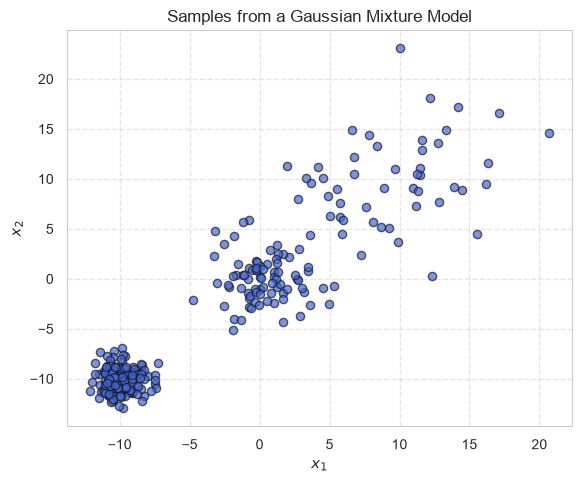

In [14]:
# Ancestral sampling from a 3-component Gaussian mixture in D = 2 dimensions:
# first the component z ~ p(z) = pi_z, then x ~ N(x | mu_z, Sigma_z)
pi = np.array([0.5, 0.3, 0.2])
mu = np.array([[-10.0, -10.0], [0.0, 0.0], [10.0, 10.0]])
Sigma = np.array([np.eye(2) * 1.0**2, np.eye(2) * 2.0**2, [[25.0, 15.0], [15.0, 25.0]]])

n_gmm = 300
z = rng.choice(len(pi), size=n_gmm, p=pi)
X_gmm = np.array([rng.multivariate_normal(mu[k], Sigma[k]) for k in z])

display(Markdown(f"Component counts: {np.bincount(z, minlength=3)} (expected {np.round(n_gmm * pi).astype(int)}); first sample $\\mathbf{{x}}$ = {np.round(X_gmm[0], 2)} from component $z$ = {z[0]}"))
hp.plot_gmm_samples(X_gmm)

# Summary: The Foundations of Probability

$$
\begin{array}{lll}
\hline
\textbf{Rule / Concept} & \textbf{Formula} & \textbf{Used for} \\[8pt]
\hline
\textbf{Sum Rule} & p(x) = \sum_y p(x, y) \quad \text{or} \quad \int p(x, y) \, \mathrm{d}y & \text{Marginalizing latent variables} \\[8pt]
\textbf{Product Rule} & p(x, y) = p(y \mid x) \, p(x) & \begin{array}{l} \text{Chain rule, autoregressive models} \\ \text{(sequence models, transformers)} \end{array} \\[8pt]
\textbf{Bayes' Theorem} & p(y \mid x) = \frac{p(x \mid y) \, p(y)}{p(x)} & \text{Posteriors, classification} \\[8pt]
\textbf{Independence} & p(x, y) = p(x) \, p(y) & \text{i.i.d. data, factorized likelihoods} \\[8pt]
\textbf{Expectation, Variance} & \mathbb{E}[f] \simeq \frac{1}{N}\sum_{n} f(x_n), \quad \mathrm{var}[x] & \text{Losses as averages, initialization} \\[8pt]
\textbf{Bernoulli, Categorical} & \mu^t (1-\mu)^{1-t}, \quad \prod_k \mu_k^{t_k} & \text{Cross-entropy for classification} \\[8pt]
\textbf{Gaussian likelihood} & \max_\mathbf{w} \ln p(\mathbf{t} \mid \mathbf{x}, \mathbf{w}) \iff \min_\mathbf{w} E(\mathbf{w}) & \text{Sum-of-squares loss for regression} \\[8pt]
\textbf{MAP} & \text{Prior } \mathcal{N}(\mathbf{0}, s^2\mathbf{I}) \iff L_2 \text{ regularization} & \text{Weight decay} \\[8pt]
\hline
\end{array}
$$

## Bridge to Information Theory

Probability theory is intimately linked to **Information Theory** *(next lecture)*, which quantifies information content, compression limits, and the difference between distributions. With $\log_2$ these quantities are measured in bits, with $\ln$ in nats:

- **Information content**: $h(x) = -\log_2 p(x)$
- **Shannon Entropy**: $\mathrm{H}[x] = -\sum_x p(x) \log_2 p(x)$ (average surprise / uncertainty)
- **Differential Entropy**: $\mathrm{H}[x] = -\int p(x) \ln p(x) \, dx$
- **Kullback–Leibler (KL) Divergence**: $\mathrm{KL}(p \parallel q) = -\int p(x) \ln\frac{q(x)}{p(x)} \, dx$ (relative entropy)
- **Mutual Information**: $\mathrm{I}[x, y] = \mathrm{KL}(p(x, y) \parallel p(x)p(y))$